# M1 — Model validation (task #3)

The SimPy model in `src/er_model.py` is checked against values that can be computed by hand.
For the configuration **mean interarrival 6 min, 6 rooms** both stations are stable (utilisation below 1),
so queueing theory gives their long-run values:

| Quantity | Formula | Value |
| --- | --- | --- |
| Arrival rate | $\lambda = 1 / 6$ | 0.1667 per min |
| Mean triage time | $E[S_T] = (2 + 4 + 6) / 3$ | 4 min |
| Mean treatment time | $E[S_R] = 0.5 \cdot 15 + 0.3 \cdot 25 + 0.2 \cdot 45$ | **24 min** |
| Nurse utilisation | $\rho_N = \lambda \, E[S_T] / 1 = 4/6$ | **0.667** |
| Room utilisation | $\rho_R = \lambda \, E[S_R] / R = 24 / (6 \cdot 6)$ | **0.667** |

Utilisation is the long-run fraction of time a server is busy. In the long run every arriving patient is
eventually served, so the work brought in per minute ($\lambda E[S]$) equals the work done per minute;
dividing by the number of servers gives the busy fraction per server. This holds for any service distribution.

Two more hand calculations check the queue itself, not only the servers:

* **Pollaczek–Khinchine (M/G/1)** — the triage station is exactly an M/G/1 queue (Poisson arrivals, one nurse,
  triangular service), so its mean wait is
  $W_q = \dfrac{\lambda \, E[S_T^2]}{2(1-\rho_N)}$ with $E[S_T^2] = \mathrm{Var}[S_T] + E[S_T]^2$ and
  $\mathrm{Var}[S_T] = (a^2+b^2+c^2-ab-ac-bc)/18$ for Tri(a, c, b).
* **Little's law** — $L_q = \lambda \, W_q$: the time-average number in the triage queue equals the arrival rate
  times the mean wait.

These are **steady-state** values. The study itself runs one day from an empty system (decision 1 in
`docs/assumptions.md`), so the comparison is done twice:

1. **Long runs** (10 replications × 100 000 min): start-up effects become negligible; the simulation must hit the
   theoretical values.
2. **One-day runs** (30 replications × 1440 min, the run length of the study): same targets, wider intervals and a
   small downward bias because every day starts empty.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

from er_model import (run_simulation, SEVERITIES, SEVERITY_PROBS, TREATMENT_PARAMS,
                      TRIAGE_LEFT, TRIAGE_MODE, TRIAGE_RIGHT)

pd.set_option("display.precision", 4)

## 1. Theoretical values

In [2]:
MEAN_IA, R = 6.0, 6
a, c, b = TRIAGE_LEFT, TRIAGE_MODE, TRIAGE_RIGHT          # Tri(min a, mode c, max b)

lam = 1 / MEAN_IA
E_triage = (a + b + c) / 3
Var_triage = (a**2 + b**2 + c**2 - a*b - a*c - b*c) / 18
E_treat = sum(p * TREATMENT_PARAMS[s][0] for s, p in zip(SEVERITIES, SEVERITY_PROBS))

rho_nurse = lam * E_triage / 1
rho_rooms = lam * E_treat / R
Wq_triage = lam * (Var_triage + E_triage**2) / (2 * (1 - rho_nurse))   # Pollaczek-Khinchine
Lq_triage = lam * Wq_triage                                            # Little's law

# Redrawing samples <= 0 (decision 3) does not change E_treat in practice:
p_nonpositive = {s: stats.norm.cdf(0, loc=m, scale=sd) for s, (m, sd) in TREATMENT_PARAMS.items()}

theory = pd.Series({
    "arrival rate (1/min)": lam,
    "mean interarrival (min)": MEAN_IA,
    "mean triage time (min)": E_triage,
    "mean treatment time (min)": E_treat,
    "nurse utilisation": rho_nurse,
    "room utilisation": rho_rooms,
    "mean triage wait Wq (min)": Wq_triage,
    "avg triage queue Lq": Lq_triage,
}, name="theory")
print("Var[triage] =", round(Var_triage, 4), "  P(normal sample <= 0):",
      {s: f"{p:.1e}" for s, p in p_nonpositive.items()})
theory.to_frame()

Var[triage] = 0.6667   P(normal sample <= 0): {'low': '2.9e-07', 'medium': '2.9e-07', 'high': '9.3e-09'}


,theory
arrival rate (1/min),0.1667
mean interarrival (min),6.0000
mean triage time (min),4.0000
mean treatment time (min),24.0000
nurse utilisation,0.6667
room utilisation,0.6667
mean triage wait Wq (min),4.1667
avg triage queue Lq,0.6944


## 2. Measuring the simulation

Utilisation and the average queue length are **time averages** of the step functions in `result.state_log`
(each row holds until the next row's time):
$\bar B = \frac{1}{T}\int_0^T B(t)\,dt$. Room utilisation is the average number of busy rooms divided by $R$.
Delays and service times are averaged over the patients who completed that step.

In [3]:
def time_average(state_log, col):
    t = state_log["time"].to_numpy()
    v = state_log[col].to_numpy(dtype=float)
    return float((v[:-1] * np.diff(t)).sum() / (t[-1] - t[0]))


def measure(res):
    p, s = res.patients, res.state_log
    T, n_rooms = res.params["run_length"], res.params["n_rooms"]
    triaged = p.dropna(subset=["triage_end"])
    treated = p.dropna(subset=["departure"])
    started = p.dropna(subset=["triage_start"])
    return {
        "arrival rate (1/min)": len(p) / T,
        "mean interarrival (min)": np.diff(np.r_[0.0, p["arrival"].to_numpy()]).mean(),
        "mean triage time (min)": (triaged["triage_end"] - triaged["triage_start"]).mean(),
        "mean treatment time (min)": (treated["departure"] - treated["room_start"]).mean(),
        "nurse utilisation": time_average(s, "nurse_busy"),
        "room utilisation": time_average(s, "rooms_busy") / n_rooms,
        "mean triage wait Wq (min)": (started["triage_start"] - started["arrival"]).mean(),
        "avg triage queue Lq": time_average(s, "triage_queue"),
    }


def compare(samples, theory, level=0.95):
    df = pd.DataFrame(samples)
    n = len(df)
    mean, sd = df.mean(), df.std(ddof=1)
    half = stats.t.ppf(0.5 + level / 2, n - 1) * sd / np.sqrt(n)
    out = pd.DataFrame({
        "theory": theory,
        "simulation": mean,
        "95% CI low": mean - half,
        "95% CI high": mean + half,
    })
    out["rel. error %"] = 100 * (out["simulation"] - out["theory"]) / out["theory"]
    out["theory in CI"] = (out["95% CI low"] <= out["theory"]) & (out["theory"] <= out["95% CI high"])
    return out

## 3. Long runs: 10 replications × 100 000 min (seeds 1–10)

In [4]:
LONG_T, LONG_N = 100_000.0, 10
long_runs = [run_simulation(n_rooms=R, mean_interarrival=MEAN_IA, run_length=LONG_T, seed=i)
             for i in range(1, LONG_N + 1)]
long_metrics = [measure(r) for r in long_runs]
long_table = compare(long_metrics, theory)
print(f"{sum(len(r.patients) for r in long_runs):,} patients in total")
long_table

166,540 patients in total


,theory,simulation,95% CI low,95% CI high,rel. error %,theory in CI
arrival rate (1/min),0.1667,0.1665,0.1658,0.1673,-0.0760,True
mean interarrival (min),6.0000,6.0045,5.9785,6.0304,0.0742,True
mean triage time (min),4.0000,4.0001,3.9950,4.0052,0.0019,True
mean treatment time (min),24.0000,24.0490,23.9642,24.1338,0.2042,True
nurse utilisation,0.6667,0.6661,0.6635,0.6688,-0.0801,True
room utilisation,0.6667,0.6674,0.6636,0.6712,0.1087,True
mean triage wait Wq (min),4.1667,4.1590,4.0651,4.2529,-0.1839,True
avg triage queue Lq,0.6944,0.6927,0.6753,0.7101,-0.2526,True


**Main checks (task #3):** nurse utilisation ≈ 0.67, room utilisation ≈ 0.67, mean treatment time ≈ 24 min.
The interarrival time, triage time, P–K waiting time and Little's law rows check the rest of the model:
if the triangular parameters were in the wrong order, or the queue were not FCFS-with-one-nurse, the P–K row would
miss.

In [5]:
# Little's law inside the simulation: Lq (time average) vs. observed arrival rate x observed mean wait
little = pd.DataFrame([{
    "seed": r.params["seed"],
    "Lq (time average)": m["avg triage queue Lq"],
    "lambda x Wq": m["arrival rate (1/min)"] * m["mean triage wait Wq (min)"],
} for r, m in zip(long_runs, long_metrics)])
little["difference %"] = 100 * (little["lambda x Wq"] / little["Lq (time average)"] - 1)
little.round(4)

,seed,Lq (time average),lambda x Wq,difference %
0,1,0.6889,0.6889,0.0007
1,2,0.7231,0.7231,-0.0000
2,3,0.7084,0.7085,0.0104
3,4,0.6535,0.6535,0.0000
4,5,0.7088,0.7088,0.0000
5,6,0.6625,0.6625,0.0000
6,7,0.6802,0.6802,0.0031
7,8,0.7136,0.7137,0.0054
8,9,0.6733,0.6733,-0.0000
9,10,0.7146,0.7146,0.0000


### Input distributions (pooled over the long runs)

In [6]:
pooled = pd.concat([r.patients for r in long_runs], ignore_index=True)
treated = pooled.dropna(subset=["departure"])
dur = treated["departure"] - treated["room_start"]
rows = []
for s, prob in zip(SEVERITIES, SEVERITY_PROBS):
    m, sd = TREATMENT_PARAMS[s]
    d = dur[treated["severity"] == s]
    rows.append({"severity": s, "share theory": prob,
                 "share sim": (pooled["severity"] == s).mean(),
                 "mean theory": m, "mean sim": d.mean(),
                 "sd theory": sd, "sd sim": d.std(), "min sim": d.min()})
inputs = pd.DataFrame(rows).set_index("severity")

tri = (pooled["triage_end"] - pooled["triage_start"]).dropna()
ia = np.concatenate([np.diff(np.r_[0.0, r.patients["arrival"].to_numpy()]) for r in long_runs])
print(f"triage time: mean {tri.mean():.4f} (theory 4), var {tri.var():.4f} (theory {Var_triage:.4f}), "
      f"min {tri.min():.3f}, max {tri.max():.3f}")
print(f"interarrival: mean {ia.mean():.4f} (theory 6), coefficient of variation {ia.std() / ia.mean():.4f} "
      f"(exponential: 1)")
inputs.round(4)

triage time: mean 4.0001 (theory 4), var 0.6688 (theory 0.6667), min 2.004, max 5.998
interarrival: mean 6.0043 (theory 6), coefficient of variation 0.9996 (exponential: 1)


,share theory,share sim,mean theory,mean sim,sd theory,sd sim,min sim
severity,,,,,,,
low,0.5,0.4981,15.0,15.0046,3.0,3.0011,2.3690
medium,0.3,0.3003,25.0,25.0083,5.0,4.9782,5.4137
high,0.2,0.2016,45.0,44.9763,8.0,8.0343,14.2695


### Convergence of the utilisations (seed 1)

The running time average $\frac{1}{t}\int_0^t B(u)\,du$ of one long run settles on the theoretical value.

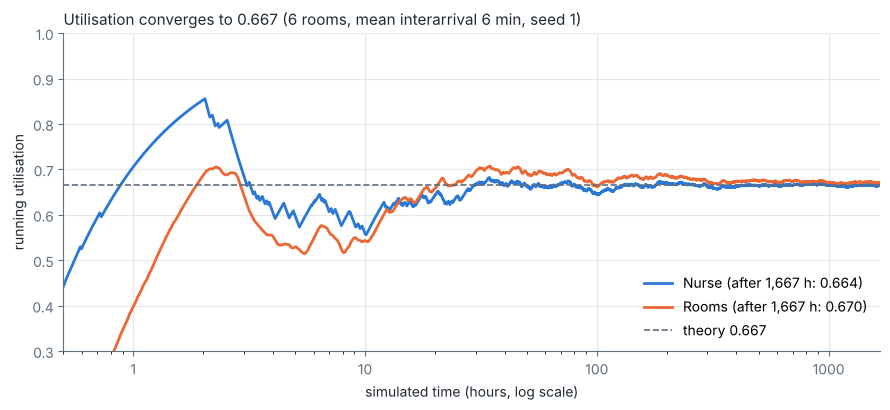

In [7]:
def running_average(state_log, col, scale=1.0):
    t = state_log["time"].to_numpy()
    v = state_log[col].to_numpy(dtype=float) / scale
    area = np.r_[0.0, np.cumsum(v[:-1] * np.diff(t))]
    keep = t > 0
    return t[keep], area[keep] / t[keep]

res = long_runs[0]
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#1f2933", "#616e7c", "#e4e7eb"

fig, ax = plt.subplots(figsize=(9, 4.2), dpi=150)
for col, scale, color, name in [("nurse_busy", 1, BLUE, "Nurse"), ("rooms_busy", R, ORANGE, "Rooms")]:
    t, y = running_average(res.state_log, col, scale)
    ax.plot(t / 60, y, color=color, lw=2, label=f"{name} (after {LONG_T / 60:,.0f} h: {y[-1]:.3f})")
ax.axhline(2 / 3, color=MUTED, lw=1.2, ls="--", label="theory 0.667")
ax.set_xscale("log")
ax.set_xlim(0.5, LONG_T / 60)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:g}"))
ax.set_ylim(0.3, 1.0)
ax.set_xlabel("simulated time (hours, log scale)", color=INK)
ax.set_ylabel("running utilisation", color=INK)
ax.set_title("Utilisation converges to 0.667 (6 rooms, mean interarrival 6 min, seed 1)",
             color=INK, fontsize=11, loc="left")
ax.grid(True, color=GRID, lw=0.8)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
for side in ("left", "bottom"):
    ax.spines[side].set_color(MUTED)
ax.tick_params(colors=MUTED)
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
fig.savefig(ROOT / "figures" / "validation_utilization.png", dpi=200)
plt.show()

## 4. One-day runs: 30 replications × 1440 min (seeds 1–30)

In [8]:
DAY_N = 30
day_runs = [run_simulation(n_rooms=R, mean_interarrival=MEAN_IA, run_length=1440.0, seed=i)
            for i in range(1, DAY_N + 1)]
day_metrics = [measure(r) for r in day_runs]
day_table = compare(day_metrics, theory)
day_table

,theory,simulation,95% CI low,95% CI high,rel. error %,theory in CI
arrival rate (1/min),0.1667,0.1629,0.1590,0.1668,-2.2500,True
mean interarrival (min),6.0000,6.1332,5.9843,6.2821,2.2195,True
mean triage time (min),4.0000,4.0022,3.9816,4.0228,0.0547,True
mean treatment time (min),24.0000,23.9867,23.7204,24.2531,-0.0553,True
nurse utilisation,0.6667,0.6501,0.6346,0.6656,-2.4829,False
room utilisation,0.6667,0.6449,0.6270,0.6629,-3.2619,False
mean triage wait Wq (min),4.1667,3.7427,3.4105,4.0749,-10.1752,False
avg triage queue Lq,0.6944,0.6142,0.5505,0.6780,-11.5545,False


In one-day runs the utilisation intervals can miss 0.667. This is expected and has two causes:

1. **Fewer or more arrivals than average.** A single day has only about 240 arrivals, so the number of arrivals itself
   varies (see the *arrival rate* row). Utilisation is proportional to the work that arrived, so a day with fewer
   arrivals has a lower utilisation. The cell below removes this effect by comparing each day's utilisation with that
   day's own offered load $\hat\lambda_{day} \, E[S] / c$.
2. **Start-up and end effects.** Every day starts empty (the first patient arrives after about 6 minutes and the rooms
   get their first patient only after triage), and work that arrives near minute 1440 is only partly done by the end.
   Both make the one-day utilisation slightly lower than the offered load. Delays are biased low as well, because the
   longest waiters may still be in the queue at the end (decision 4).

Both effects disappear in the long runs above, which is why those hit the theory.

In [9]:
day_m = pd.DataFrame(day_metrics)
offered = pd.DataFrame({
    "simulated": [day_m["nurse utilisation"].mean(), day_m["room utilisation"].mean()],
    "offered load of the same days": [(day_m["arrival rate (1/min)"] * E_triage).mean(),
                                      (day_m["arrival rate (1/min)"] * E_treat / R).mean()],
    "theory (long run)": [rho_nurse, rho_rooms],
}, index=["nurse", "rooms"])
offered["simulated / offered"] = offered["simulated"] / offered["offered load of the same days"]
offered.round(4)

,simulated,offered load of the same days,theory (long run),simulated / offered
nurse,0.6501,0.6517,0.6667,0.9976
rooms,0.6449,0.6517,0.6667,0.9896


## 5. Summary

In [10]:
MAIN = ["nurse utilisation", "room utilisation", "mean treatment time (min)"]
summary = pd.DataFrame({
    "theory": theory[MAIN],
    "long runs": long_table.loc[MAIN, "simulation"],
    "long-run 95% CI": [f"[{lo:.4f}, {hi:.4f}]" for lo, hi in
                        long_table.loc[MAIN, ["95% CI low", "95% CI high"]].to_numpy()],
    "long-run error %": long_table.loc[MAIN, "rel. error %"],
    "one-day runs": day_table.loc[MAIN, "simulation"],
    "one-day error %": day_table.loc[MAIN, "rel. error %"],
})

# The validation fails loudly if the model drifts from the theory.
assert (long_table.loc[MAIN, "rel. error %"].abs() < 2).all(), long_table
assert (long_table["rel. error %"].abs() < 5).all(), long_table
assert (little["difference %"].abs() < 1).all(), little
assert (inputs["share sim"] - inputs["share theory"]).abs().max() < 0.01
print("All validation checks passed.")
summary.round(4)

All validation checks passed.


,theory,long runs,long-run 95% CI,long-run error %,one-day runs,one-day error %
nurse utilisation,0.6667,0.6661,"[0.6635, 0.6688]",-0.0801,0.6501,-2.4829
room utilisation,0.6667,0.6674,"[0.6636, 0.6712]",0.1087,0.6449,-3.2619
mean treatment time (min),24.0000,24.0490,"[23.9642, 24.1338]",0.2042,23.9867,-0.0553
